## Week 0: EDA & Data Setup

I will be performing week 1 to 6 concepts on an insurance vehicle claims dataset from https://data.mendeley.com/datasets/992mh7dk9y/2.

This dataset will be used to predict claims fraud.

In [1]:
%pip install pandas numpy matplotlib scikit-learn statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict, GridSearchCV, validation_curve)
from sklearn.linear_model import (LinearRegression, LogisticRegression, LogisticRegressionCV,
                                  RidgeCV, LassoCV, ElasticNetCV)
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import LinearSVC, SVC, SVR
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             log_loss, mean_squared_error, r2_score, roc_auc_score, roc_curve,
                             RocCurveDisplay)

Note: you may need to restart the kernel to use updated packages.


In [2]:
df = pd.read_csv("insurance_claims.csv")

# Dropping irrelevant variables to the potential models
df = df.drop(columns=["_c39", "policy_number", "insured_zip",
                      "incident_location", "policy_bind_date", "incident_date"])

# Cleaining 
df = df.replace("?", "Unknown")
df = df.fillna("Unknown")

# Changing the year of the car model to the vehicle age
df["vehicle_age"] = 2015 - df["auto_year"]
df = df.drop(columns=["auto_year"])

df["fraud"] = (df["fraud_reported"] == "Y").astype(int)
df = df.drop(columns=["fraud_reported"])

print(df.shape)
df.head()

(1000, 34)


,months_as_customer,age,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_sex,insured_education_level,insured_occupation,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,vehicle_age,fraud
0,328,48,OH,250/500,1000,1406.91,0,MALE,MD,craft-repair,...,2,YES,71610,6510,13020,52080,Saab,92x,11,1
1,228,42,IN,250/500,2000,1197.22,5000000,MALE,MD,machine-op-inspct,...,0,Unknown,5070,780,780,3510,Mercedes,E400,8,1
2,134,29,OH,100/300,2000,1413.14,5000000,FEMALE,PhD,sales,...,3,NO,34650,7700,3850,23100,Dodge,RAM,8,0
3,256,41,IL,250/500,2000,1415.74,6000000,FEMALE,PhD,armed-forces,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,1,1
4,228,44,IL,500/1000,1000,1583.91,6000000,MALE,Associate,sales,...,1,NO,6500,1300,650,4550,Accura,RSX,6,0


In [3]:
# Number of fraud claims in this dataset
print(df["fraud"].value_counts())

fraud
0    753
1    247
Name: count, dtype: int64


In [4]:
# Encoding all categorical variables
encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print(encoded.shape)
encoded.head()

(1000, 145)


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,...,auto_model_Pathfinder,auto_model_RAM,auto_model_RSX,auto_model_Silverado,auto_model_TL,auto_model_Tahoe,auto_model_Ultima,auto_model_Wrangler,auto_model_X5,auto_model_X6
0,328,48,1000,1406.91,0,53300,0,5,1,1,...,0,0,0,0,0,0,0,0,0,0
1,228,42,2000,1197.22,5000000,0,0,8,1,0,...,0,0,0,0,0,0,0,0,0,0
2,134,29,2000,1413.14,5000000,35100,0,7,3,2,...,0,1,0,0,0,0,0,0,0,0
3,256,41,2000,1415.74,6000000,48900,-62400,5,1,1,...,0,0,0,0,0,1,0,0,0,0
4,228,44,1000,1583.91,6000000,66000,-46000,20,1,0,...,0,0,1,0,0,0,0,0,0,0


In [5]:
# Too many variables now, many of which have barely any "1s". 
# If the category has less than 50 claims, I'm changing the value to "other"

for col in df.select_dtypes(include="object").columns:
    counts = df[col].value_counts()
    rare = counts[counts < 50].index
    df[col] = df[col].replace(rare, "Other")

encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# This should reduce the number of variables
print(encoded.shape)
encoded.head()

(1000, 98)


/tmp/ipykernel_8804/3806971926.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,...,auto_make_Dodge,auto_make_Ford,auto_make_Honda,auto_make_Jeep,auto_make_Mercedes,auto_make_Nissan,auto_make_Saab,auto_make_Suburu,auto_make_Toyota,auto_make_Volkswagen
0,328,48,1000,1406.91,0,53300,0,5,1,1,...,0,0,0,0,0,0,1,0,0,0
1,228,42,2000,1197.22,5000000,0,0,8,1,0,...,0,0,0,0,1,0,0,0,0,0
2,134,29,2000,1413.14,5000000,35100,0,7,3,2,...,1,0,0,0,0,0,0,0,0,0
3,256,41,2000,1415.74,6000000,48900,-62400,5,1,1,...,0,0,0,0,0,0,0,0,0,0
4,228,44,1000,1583.91,6000000,66000,-46000,20,1,0,...,0,0,0,0,0,0,0,0,0,0


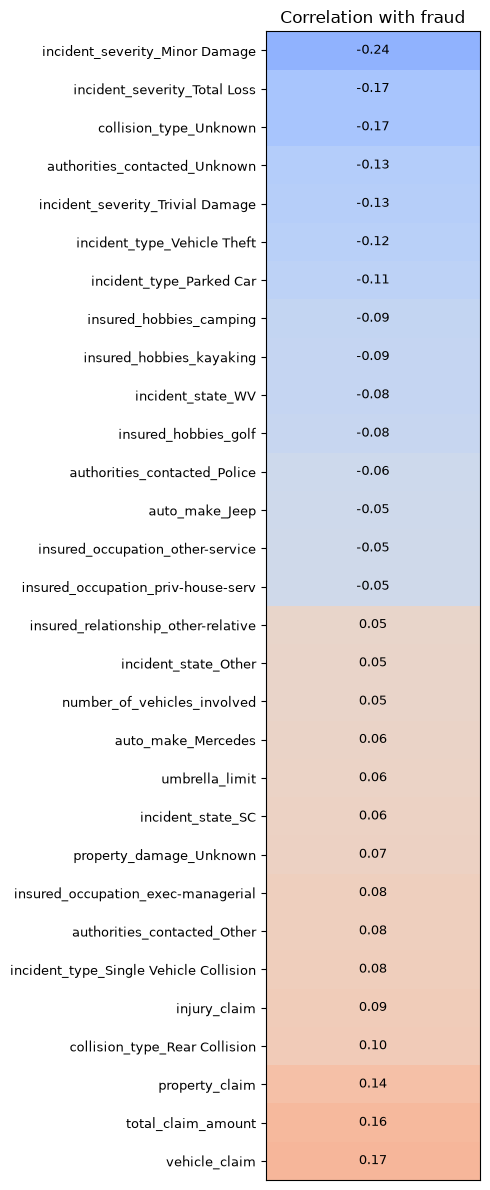

In [6]:
# Looking at top correlated variables with Fraud
n = 15
fraud_corr = encoded.corr()["fraud"].drop("fraud").sort_values()
top = pd.concat([fraud_corr.head(n), fraud_corr.tail(n)])

plt.figure(figsize=(5, 12))
plt.imshow(top.to_frame(), cmap="coolwarm", vmin=-0.5, vmax=0.5, aspect="auto")
plt.yticks(range(len(top)), top.index, fontsize=9)
plt.xticks([])
for i, value in enumerate(top.values):
    plt.text(0, i, f"{value:.2f}", ha="center", va="center", fontsize=9)
plt.title("Correlation with fraud")
plt.tight_layout()
plt.show()

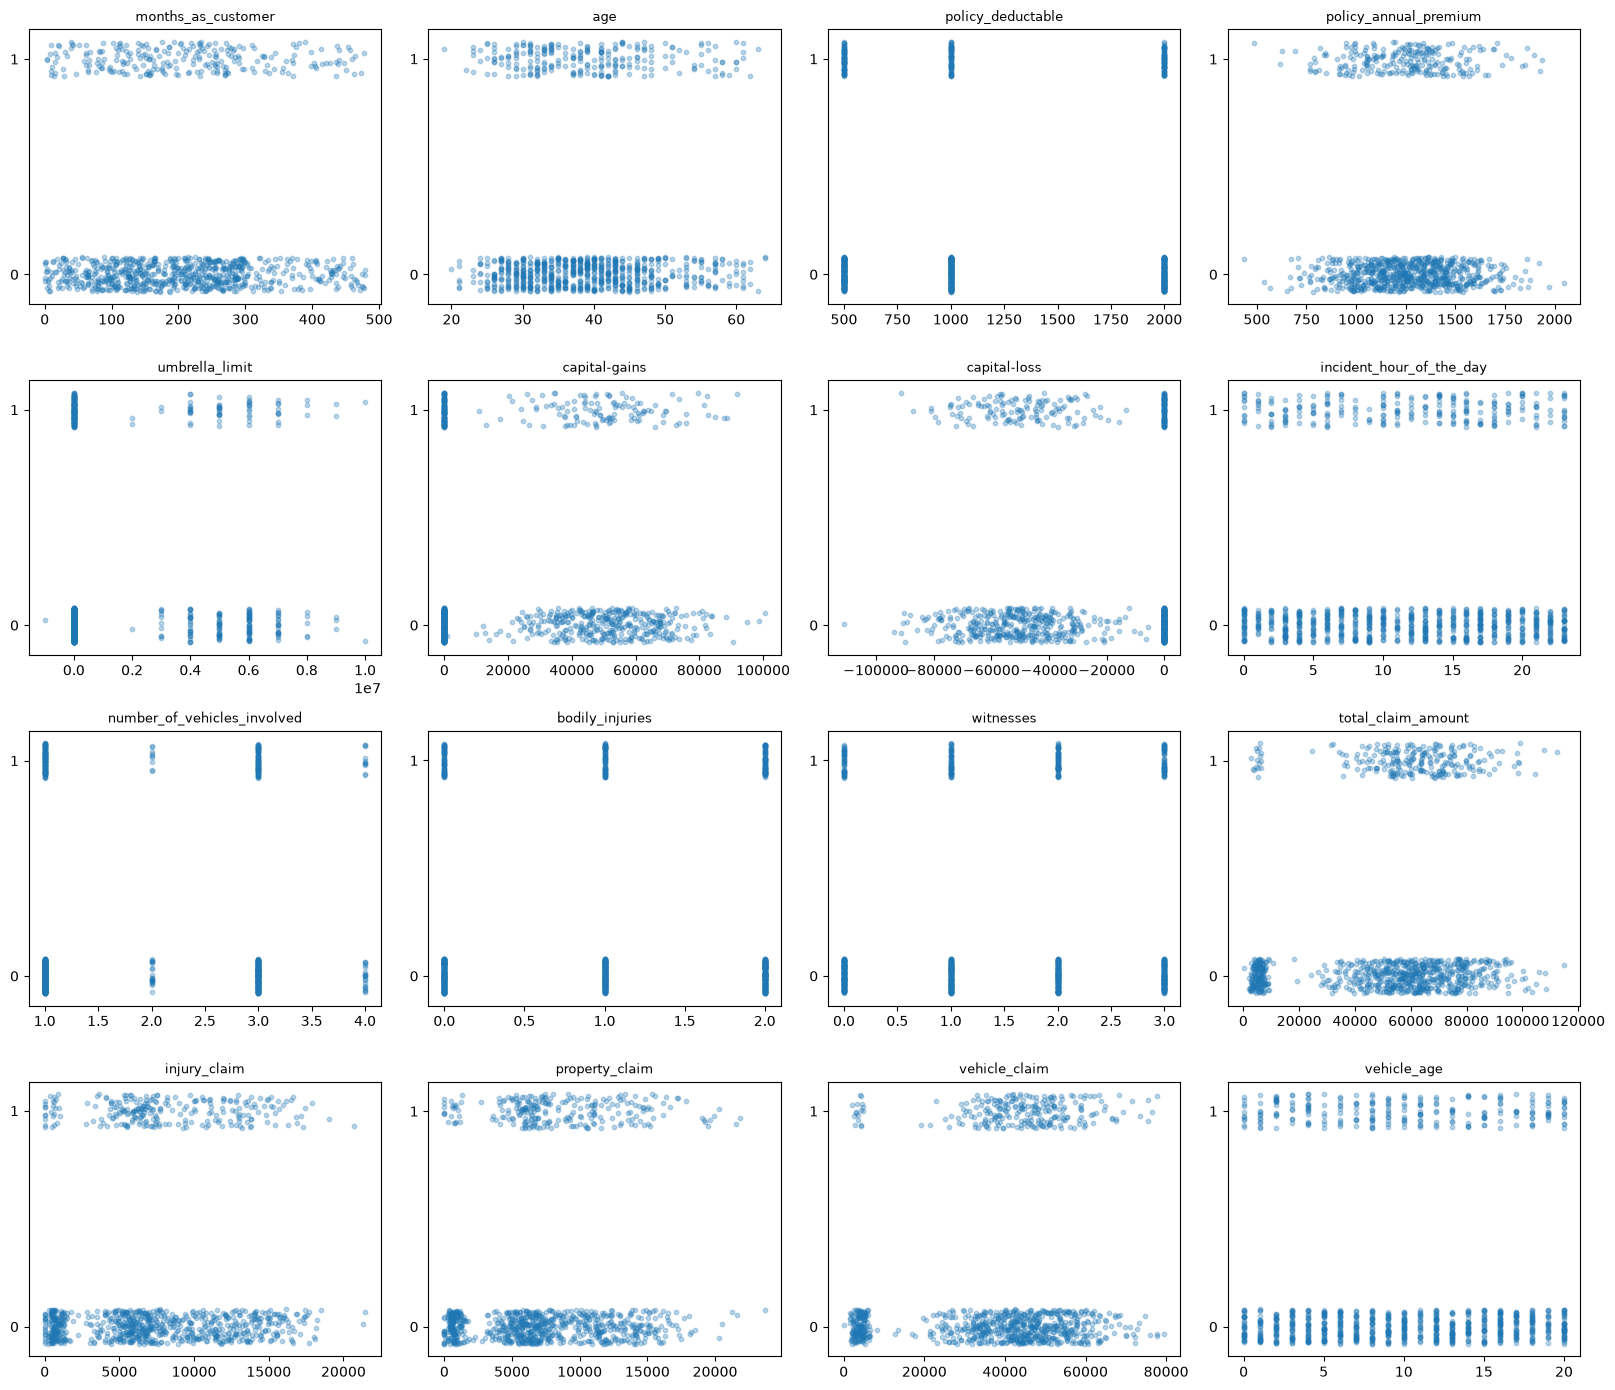

In [7]:
# Showing a grid of small scatterplots, one for each numeric column, with fraud on the vertical axis.

np.random.seed(0)

num_cols = df.select_dtypes(include="number").drop(columns=["fraud"]).columns
rows = (len(num_cols) + 3) // 4

fig, axes = plt.subplots(rows, 4, figsize=(16, 3.5 * rows))
for ax, col in zip(axes.flatten(), num_cols):
    wiggle = np.random.uniform(-0.08, 0.08, len(df))
    ax.scatter(df[col], df["fraud"] + wiggle, alpha=0.3, s=10)
    ax.set_title(col, fontsize=9)
    ax.set_yticks([0, 1])
plt.tight_layout()
plt.show()

## Week 1: Polynomial and Interaction Terms

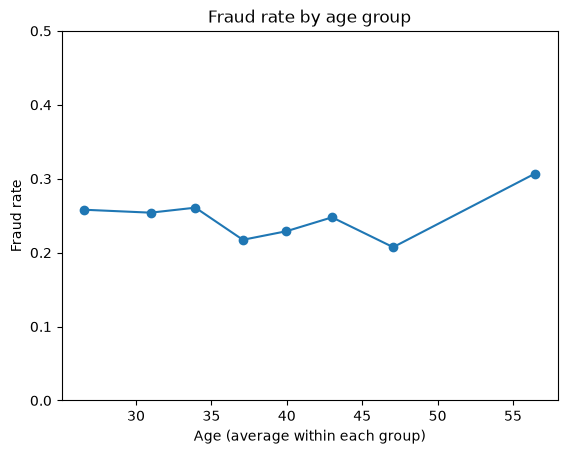

In [8]:
# Showing an example of scatterplots I used to see relationships between X and y to see if we could try a polynomial term
# Splitting customer age range into 8 groups for the visual
# I see a little curvature in customer age & fraud! 
df["age_group"] = pd.qcut(df["age"], 8)

rate = df.groupby("age_group", observed=True)["fraud"].mean()      # fraud rate in each group
middle = df.groupby("age_group", observed=True)["age"].mean()      # avg age in each group

plt.plot(middle, rate, marker="o")
plt.xlabel("Age (average within each group)")
plt.ylabel("Fraud rate")
plt.title("Fraud rate by age group")
plt.ylim(0, 0.5)
plt.show()

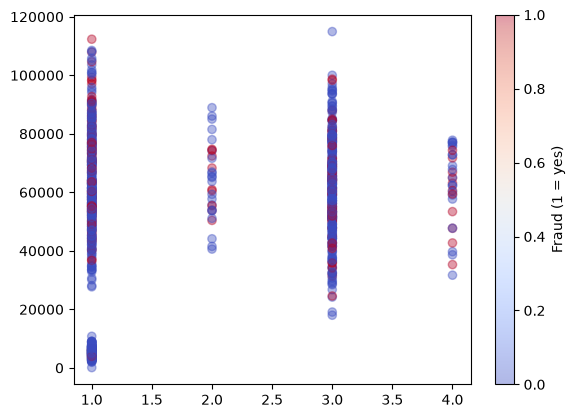

In [9]:
# Showing an example of scatterplots I used to help me determine potential interaction terms
# I looked for relationships between the two independent variables that could imapct fraud

plt.scatter(df["number_of_vehicles_involved"], df["total_claim_amount"],
            c=df["fraud"], cmap="coolwarm", alpha=0.4)
plt.colorbar(label="Fraud (1 = yes)")

In [10]:
# Baseline Logistic regression model

X = encoded.drop(columns="fraud")
y = encoded["fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

base_scores = cross_val_score(model, X_train, y_train, cv=folds, scoring="roc_auc")
print(f"Baseline AUC: {base_scores.mean():.3f}")

Baseline AUC: 0.751


In [11]:
# Built this function to test adding interaction and squared terms
def test_term(col_a, col_b):
    X_new = X_train.copy()
    X_new["new_term"] = X_train[col_a] * X_train[col_b]
    new_scores = cross_val_score(model, X_new, y_train, cv=folds, scoring="roc_auc")
    diff = new_scores - base_scores
    print(f"{col_a} x {col_b}")
    print(f"  AUC: {base_scores.mean():.3f} -> {new_scores.mean():.3f}  (gain {diff.mean():+.4f})")
    print(f"  Folds improved: {(diff > 0).sum()} of {len(diff)}")

test_term("total_claim_amount", "number_of_vehicles_involved")
test_term("total_claim_amount", "incident_severity_Minor Damage")
test_term("injury_claim", "bodily_injuries")
test_term("months_as_customer", "total_claim_amount")
test_term("age","age")
test_term("vehicle_age","vehicle_age")

total_claim_amount x number_of_vehicles_involved
  AUC: 0.751 -> 0.749  (gain -0.0013)
  Folds improved: 3 of 15
total_claim_amount x incident_severity_Minor Damage
  AUC: 0.751 -> 0.750  (gain -0.0006)
  Folds improved: 6 of 15
injury_claim x bodily_injuries
  AUC: 0.751 -> 0.750  (gain -0.0004)
  Folds improved: 5 of 15
months_as_customer x total_claim_amount
  AUC: 0.751 -> 0.750  (gain -0.0005)
  Folds improved: 9 of 15
age x age
  AUC: 0.751 -> 0.750  (gain -0.0004)
  Folds improved: 3 of 15
vehicle_age x vehicle_age
  AUC: 0.751 -> 0.752  (gain +0.0012)
  Folds improved: 8 of 15


Only vehicle age squared actually improved the AUC!

## Week 2: Lasso, ridge, elastic net regression 

Since this model has a binary dependent variable, I spent my time with week 2 concepts on the Claude dataset.

## Week 3: Forward and backward selection, principal component regression, partial least squares regression

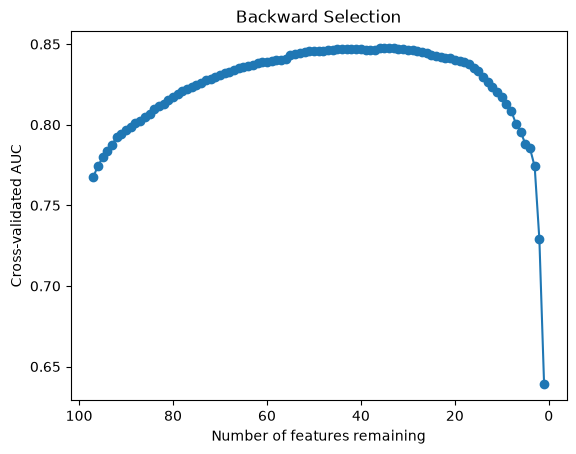

In [12]:
# Adding Age sqaured to the model
X["age_sq"] = X["vehicle_age"]**2

# stratify to keep the same fraud rate in both splits the same (around 25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Backward selection. Wrote my own loop so I can track AUC at every step
logit = LogisticRegression(max_iter=1000)

Xs_train = pd.DataFrame(X_train_s, columns=X_train.columns)

selected = list(Xs_train.columns)
n_left = []
cv_scores = []
feature_lists = {} 

# Keeps the removal that leaves the best AUC
while len(selected) > 1:
    best_score = 0
    for feature in selected:
        candidate = [f for f in selected if f != feature]
        score = cross_val_score(logit, Xs_train[candidate], y_train, cv=3, scoring="roc_auc").mean()
        if score > best_score:
            best_score = score
            best_candidate = candidate
    selected = best_candidate

    n_left.append(len(selected))
    cv_scores.append(best_score)
    feature_lists[len(selected)] = selected.copy()

plt.plot(n_left, cv_scores, marker="o")
plt.gca().invert_xaxis()
plt.xlabel("Number of features remaining")
plt.ylabel("Cross-validated AUC")
plt.title("Backward Selection")
plt.show()

In [13]:
# Based off the above visual, I only wanted to include the top 18 variables. 
# As you can see, the model's AUC seems to be at its peak from 40 to 18 features remaining. 
# Knowing that, I only kept those 18 so that I can have as few variable to make the best predictions.
kept_features = feature_lists[18]
print(kept_features)
print("Cross-validated AUC:", round(cv_scores[n_left.index(18)], 3))

['umbrella_limit', 'insured_occupation_handlers-cleaners', 'insured_hobbies_bungie-jumping', 'insured_hobbies_camping', 'insured_hobbies_exercise', 'insured_hobbies_golf', 'insured_hobbies_hiking', 'insured_hobbies_kayaking', 'insured_hobbies_movies', 'insured_hobbies_paintball', 'insured_hobbies_reading', 'insured_hobbies_video-games', 'incident_severity_Minor Damage', 'incident_severity_Total Loss', 'incident_severity_Trivial Damage', 'incident_state_NY', 'incident_state_WV', 'auto_make_BMW']
Cross-validated AUC: 0.839


## Week 4: Logistic regression and feature scaling

In [14]:
# Only keeping the variables from week 3 after backwards selection. 18 variables
X = encoded[kept_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logit = LogisticRegression(max_iter=1000)

# 5-fold cross-validation
cv_pred = cross_val_predict(logit, X_train_s, y_train,
                            cv=StratifiedKFold(5, shuffle=True, random_state=1))

print("Accuracy:", accuracy_score(y_train, cv_pred))
print(classification_report(y_train, cv_pred))
print(confusion_matrix(y_train, cv_pred))

Accuracy: 0.82
              precision    recall  f1-score   support

           0       0.85      0.92      0.89       602
           1       0.68      0.51      0.58       198

    accuracy                           0.82       800
   macro avg       0.77      0.71      0.73       800
weighted avg       0.81      0.82      0.81       800

[[556  46]
 [ 98 100]]


In [15]:
logit.fit(X_train_s, y_train)
test_pred = logit.predict(X_test_s)

print("Test accuracy:", accuracy_score(y_test, test_pred))
print(classification_report(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

Test accuracy: 0.8
              precision    recall  f1-score   support

           0       0.84      0.91      0.87       151
           1       0.63      0.45      0.52        49

    accuracy                           0.80       200
   macro avg       0.73      0.68      0.70       200
weighted avg       0.79      0.80      0.79       200

[[138  13]
 [ 27  22]]


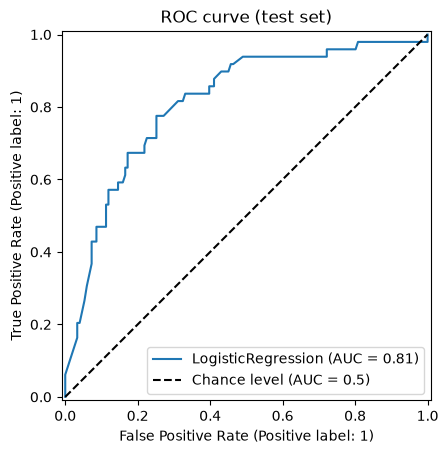

In [16]:
# I'm showing the below ROC plot to show how well the model separates fraud from non-fraud at every cutoff

logit.fit(X_train_s, y_train)
RocCurveDisplay.from_estimator(logit, X_test_s, y_test, plot_chance_level=True)
plt.title("ROC curve (test set)")
plt.show()

## Week 5: Support vector machines, the kernel trick, and regularization

In [17]:
# Linear SVM (no kernel)
linear_model = make_pipeline(StandardScaler(), LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=42))
linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)

print("Linear SVM")
print("Accuracy:", round(accuracy_score(y_test, pred_linear), 3))
print("AUC:", round(roc_auc_score(y_test, linear_model.decision_function(X_test)), 3))
print(classification_report(y_test, pred_linear))

# Kernel SVM (RBF kernel)
kernel_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=5.0, gamma="scale"))
kernel_model.fit(X_train, y_train)
pred_kernel = kernel_model.predict(X_test)

print("RBF Kernel SVM")
print("Accuracy:", round(accuracy_score(y_test, pred_kernel), 3))
print("AUC:", round(roc_auc_score(y_test, kernel_model.decision_function(X_test)), 3))
print(classification_report(y_test, pred_kernel))

# Tuning C and gamma with cross-validation
linear_grid = GridSearchCV(
    make_pipeline(StandardScaler(), LinearSVC(dual=False, max_iter=5000, random_state=42)),
    param_grid={"linearsvc__C": [0.001, 0.01, 0.1, 1, 10]},
    scoring="roc_auc", cv=5)
linear_grid.fit(X_train, y_train)

rbf_grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    param_grid={"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.0001, 0.001, 0.01, "scale"]},
    scoring="roc_auc", cv=5)
rbf_grid.fit(X_train, y_train)

print("Best linear C:", linear_grid.best_params_, "| CV AUC:", round(linear_grid.best_score_, 3))
print("Best RBF settings:", rbf_grid.best_params_, "| CV AUC:", round(rbf_grid.best_score_, 3))

# Test results for the tuned models
for name, grid in [("Tuned linear SVM", linear_grid), ("Tuned RBF SVM", rbf_grid)]:
    pred = grid.predict(X_test)
    print(name, "| Test AUC:", round(roc_auc_score(y_test, grid.decision_function(X_test)), 3),
          "| Test F1:", round(f1_score(y_test, pred), 3),
          "| Accuracy:", round(accuracy_score(y_test, pred), 3))
print(confusion_matrix(y_test, rbf_grid.predict(X_test)))
print(classification_report(y_test, linear_grid.predict(X_test)))


Linear SVM
Accuracy: 0.8
AUC: 0.822
              precision    recall  f1-score   support

           0       0.84      0.91      0.87       151
           1       0.62      0.47      0.53        49

    accuracy                           0.80       200
   macro avg       0.73      0.69      0.70       200
weighted avg       0.79      0.80      0.79       200

RBF Kernel SVM
Accuracy: 0.815
AUC: 0.774
              precision    recall  f1-score   support

           0       0.85      0.92      0.88       151
           1       0.67      0.49      0.56        49

    accuracy                           0.81       200
   macro avg       0.76      0.71      0.72       200
weighted avg       0.80      0.81      0.80       200

Best linear C: {'linearsvc__C': 0.01} | CV AUC: 0.836
Best RBF settings: {'svc__C': 0.1, 'svc__gamma': 0.0001} | CV AUC: 0.825
Tuned linear SVM | Test AUC: 0.82 | Test F1: 0.518 | Accuracy: 0.795
Tuned RBF SVM | Test AUC: 0.816 | Test F1: 0.0 | Accuracy: 0.755
[[151  

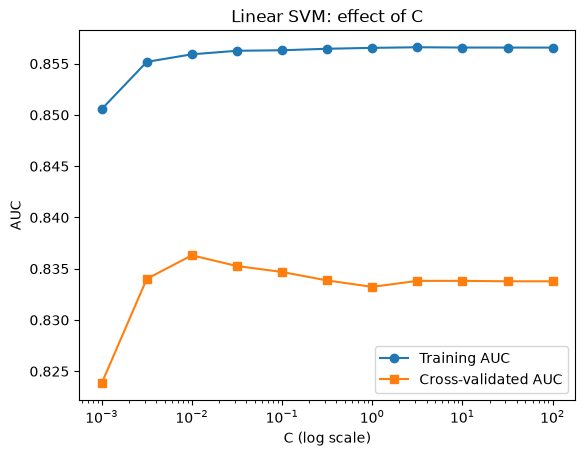

In [18]:
# Showing how the SVM’s penalty setting C affects overfitting.
# As you can see, the training AUC keeps rising as C grows, while cross-validated AUC peaks and then falls.
C_values = np.logspace(-3, 2, 11)
model = make_pipeline(StandardScaler(), LinearSVC(dual=False, max_iter=5000, random_state=42))

train_scores, cv_scores = validation_curve(model, X_train, y_train, param_name="linearsvc__C",
                                           param_range=C_values, scoring="roc_auc", cv=5)

plt.semilogx(C_values, train_scores.mean(axis=1), marker="o", label="Training AUC")
plt.semilogx(C_values, cv_scores.mean(axis=1), marker="s", label="Cross-validated AUC")
plt.xlabel("C (log scale)")
plt.ylabel("AUC")
plt.title("Linear SVM: effect of C")
plt.legend()
plt.show()

## Week 6: Decision trees and random forests

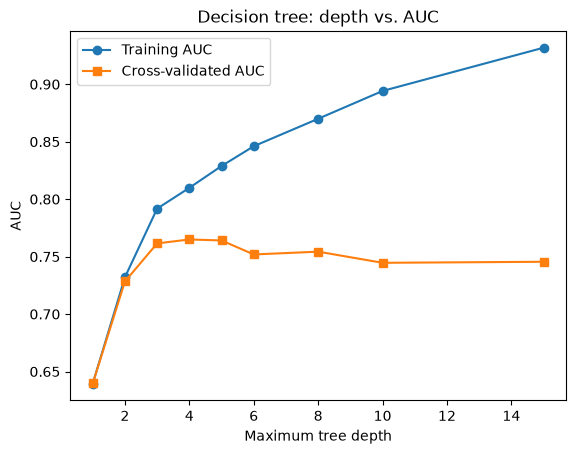

Best tree settings: {'max_depth': 8, 'min_samples_leaf': 10} | CV AUC: 0.773


Best forest settings: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5} | CV AUC: 0.807
Tuned tree | Train AUC: 0.841 | Test AUC: 0.781 | F1: 0.512 | Accuracy: 0.79 | Log loss: 1.106
Tuned forest | Train AUC: 0.866 | Test AUC: 0.819 | F1: 0.5 | Accuracy: 0.8 | Log loss: 0.438
[[140  11]
 [ 29  20]]


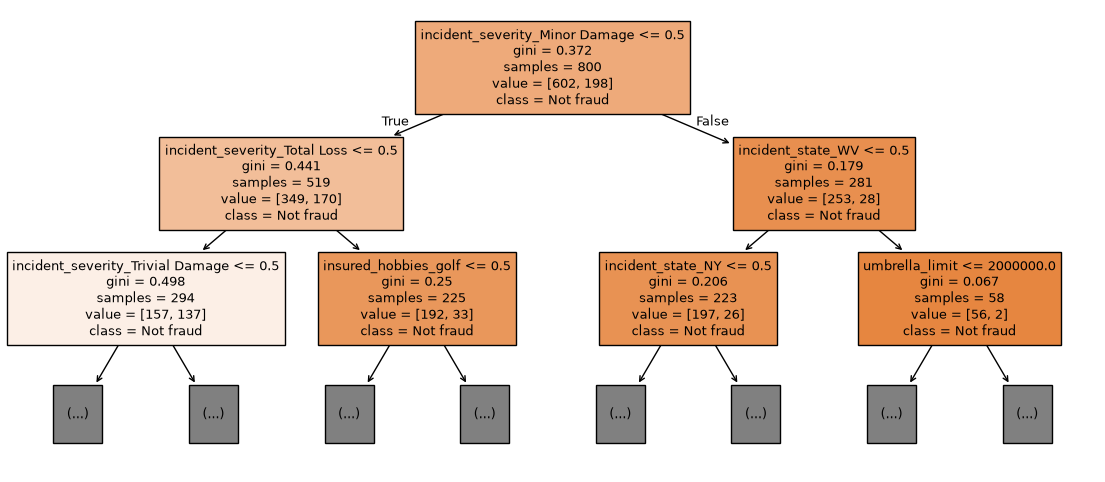

incident_severity_Minor Damage      0.312
incident_severity_Total Loss        0.210
incident_severity_Trivial Damage    0.132
umbrella_limit                      0.065
incident_state_WV                   0.047
insured_hobbies_golf                0.038
incident_state_NY                   0.028
insured_hobbies_kayaking            0.025
insured_hobbies_camping             0.023
insured_hobbies_exercise            0.021
dtype: float64
incident_severity_Minor Damage      0.198
incident_severity_Total Loss        0.164
incident_severity_Trivial Damage    0.075
insured_hobbies_camping             0.018
umbrella_limit                      0.016
incident_state_WV                   0.009
insured_hobbies_video-games         0.006
insured_hobbies_movies              0.004
insured_hobbies_exercise            0.003
insured_hobbies_kayaking            0.002
dtype: float64


In [19]:
# Tree size: training vs. cross-validated AUC
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15]
train_auc = []
cv_auc = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    cv_auc.append(cross_val_score(tree, X_train, y_train, cv=5, scoring="roc_auc").mean())

plt.plot(depths, train_auc, marker="o", label="Training AUC")
plt.plot(depths, cv_auc, marker="s", label="Cross-validated AUC")
plt.xlabel("Maximum tree depth")
plt.ylabel("AUC")
plt.title("Decision tree: depth vs. AUC")
plt.legend()
plt.show()

# Tuning the tree with cross-validation
tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         param_grid={"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [1, 5, 10, 20]},
                         scoring="roc_auc", cv=5)
tree_grid.fit(X_train, y_train)
best_tree = tree_grid.best_estimator_
print("Best tree settings:", tree_grid.best_params_, "| CV AUC:", round(tree_grid.best_score_, 3))

# Tuning the random forest model
forest_grid = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                           param_grid={"max_depth": [5, 10, None], "min_samples_leaf": [1, 5], "max_features": ["sqrt", 0.3]},
                           scoring="roc_auc", cv=5)
forest_grid.fit(X_train, y_train)
best_forest = forest_grid.best_estimator_
print("Best forest settings:", forest_grid.best_params_, "| CV AUC:", round(forest_grid.best_score_, 3))

# Comparing on the test set
unlimited = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)    # no size limit, for comparison

# Comparing on the test set
for name, m in [("Tuned tree", best_tree), ("Tuned forest", best_forest)]:
    probs = m.predict_proba(X_test)[:, 1]
    pred = m.predict(X_test)
    print(name,
          "| Train AUC:", round(roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]), 3),
          "| Test AUC:", round(roc_auc_score(y_test, probs), 3),
          "| F1:", round(f1_score(y_test, pred), 3),
          "| Accuracy:", round(accuracy_score(y_test, pred), 3),
          "| Log loss:", round(log_loss(y_test, probs), 3))

print(confusion_matrix(y_test, best_forest.predict(X_test)))

# Drawing the tree
plt.figure(figsize=(14, 6))
plot_tree(best_tree, feature_names=X_train.columns, class_names=["Not fraud", "Fraud"],
          max_depth=2, filled=True, fontsize=9)
plt.show()

# Feature Importance
# Method 1: Impurity
impurity = pd.Series(best_forest.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
print(impurity.round(3))

# Method 2: Permutation
perm = permutation_importance(best_forest, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
shuffled = pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False).head(10)
print(shuffled.round(3))